# Twitter Sentiment Analysis - Exploratory Data Analysis

This notebook explores the [Sentiment140](http://help.sentiment140.com/for-students) dataset before any model is trained.

**Goals**
1. Understand the structure and quality of the data
2. Check whether the classes are balanced
3. Look at tweet lengths
4. See what the text looks like before and after preprocessing
5. Find the most frequent words in each sentiment

> Before running: prepare the dataset with `python -m src.download_data` (creates `data/sentiment140.csv`).

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Make the `src` package importable when the notebook runs from the notebooks/ folder.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, LABELS, RANDOM_STATE
from src.error_analysis import mask_personal_data
from src.preprocessing import preprocess_series

sns.set_theme(style="whitegrid")

## 1. Loading the data

The processed file has two columns: `target` (0 = negative, 1 = positive) and `text` (the tweet).

In [2]:
df = pd.read_csv(DATA_PATH)
df["sentiment"] = df["target"].map(LABELS)

print(f"Rows: {len(df):,} | Columns: {list(df.columns)}")
# @handles and links are masked in what is displayed, so no real username appears in the outputs.
df.head().assign(text=lambda table: table["text"].map(mask_personal_data))

Rows: 1,600,000 | Columns: ['target', 'text', 'sentiment']


,target,text,sentiment
0,0,"@user <link> - Awww, that's a bummer. You sho...",Negative
1,0,is upset that he can't update his Facebook by ...,Negative
2,0,@user I dived many times for the ball. Managed...,Negative
3,0,my whole body feels itchy and like its on fire,Negative
4,0,"@user no, it's not behaving at all. i'm mad. w...",Negative


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 3 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   target     1600000 non-null  int64
 1   text       1600000 non-null  str  
 2   sentiment  1600000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 36.6 MB


## 2. Class balance

A model trained on very unbalanced data tends to favor the majority class. According to the dataset
documentation, the training set has the same number of positive and negative tweets - let's confirm it.

sentiment
Negative    800000
Positive    800000
Name: count, dtype: int64


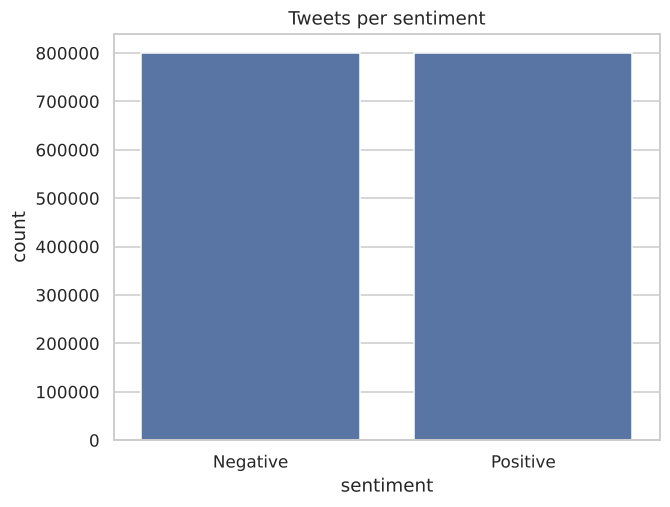

In [4]:
print(df["sentiment"].value_counts())

ax = sns.countplot(data=df, x="sentiment", order=list(LABELS.values()))
ax.set_title("Tweets per sentiment")
plt.show()

## 3. Data quality

Missing values and duplicated tweets can distort both training and evaluation.

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print(f"\nDuplicated tweets: {df['text'].duplicated().sum():,}")

Missing values per column:
target       0
text         0
sentiment    0
dtype: int64

Duplicated tweets: 18,534


## 4. Tweet length

Tweets were limited to 140 characters when this dataset was collected. Does length differ between positive and negative tweets?

In [6]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()

df[["n_chars", "n_words"]].describe()

,n_chars,n_words
count,1.600000e+06,1.600000e+06
mean,7.409011e+01,1.317615e+01
std,3.644114e+01,6.957978e+00
min,6.000000e+00,1.000000e+00
25%,4.400000e+01,7.000000e+00
50%,6.900000e+01,1.200000e+01
75%,1.040000e+02,1.900000e+01
max,3.740000e+02,6.400000e+01


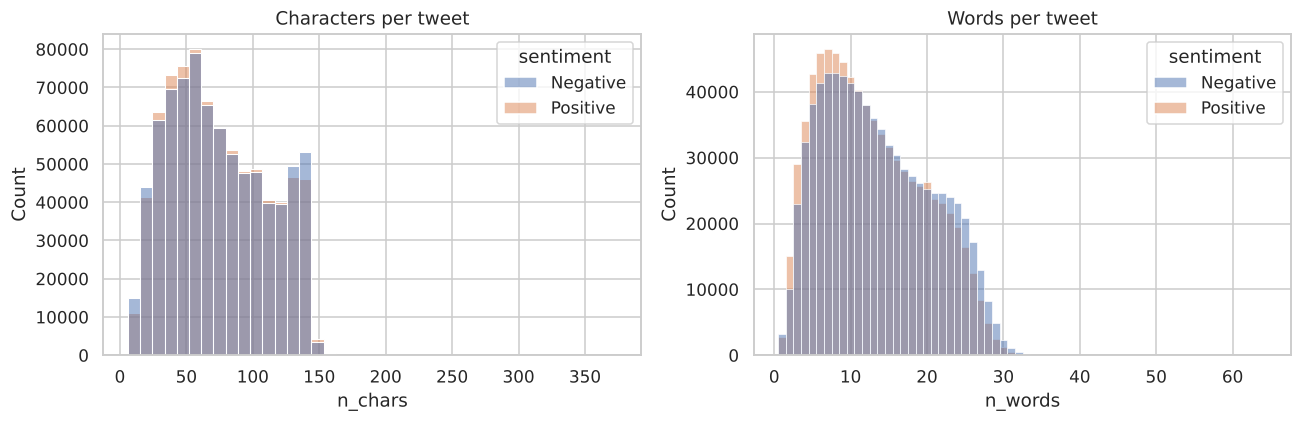

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="n_chars", hue="sentiment", bins=40, ax=axes[0])
axes[0].set_title("Characters per tweet")

sns.histplot(data=df, x="n_words", hue="sentiment", discrete=True, ax=axes[1])
axes[1].set_title("Words per tweet")

plt.tight_layout()
plt.show()

## 5. Before and after preprocessing

The full dataset has 1.6 million tweets, so the next steps use a random sample to keep the notebook fast.

In [8]:
sample = df.sample(n=min(50_000, len(df)), random_state=RANDOM_STATE).copy()
sample["clean_text"] = preprocess_series(sample["text"])

sample[["text", "clean_text"]].head(8).assign(text=lambda table: table["text"].map(mask_personal_data))

,text,clean_text
541200,@user AHHH I HOPE YOUR OK!!!,ahh hope ok
750,"@user cool , i have no tweet apps for my razr 2",cool no tweet apps razr
766711,@user i know just family drama. its lame.hey ...,know just family drama lame hey time hang kim ...
285055,School email won't open and I have geography ...,school email won't open geography stuff revise...
705995,upper airways problem,upper airways problem
379611,Going to miss Pastor's sermon on Faith...,going miss pastor's sermon faith
1189018,on lunch....dj should come eat with me,lunch dj come eat
667030,@user oh why are you feeling like that?,oh feeling like


In [9]:
empty = (sample["clean_text"] == "").sum()
print(f"Tweets that became empty after preprocessing: {empty:,} ({empty / len(sample):.2%})")

Tweets that became empty after preprocessing: 301 (0.60%)


## 6. Most frequent words per sentiment

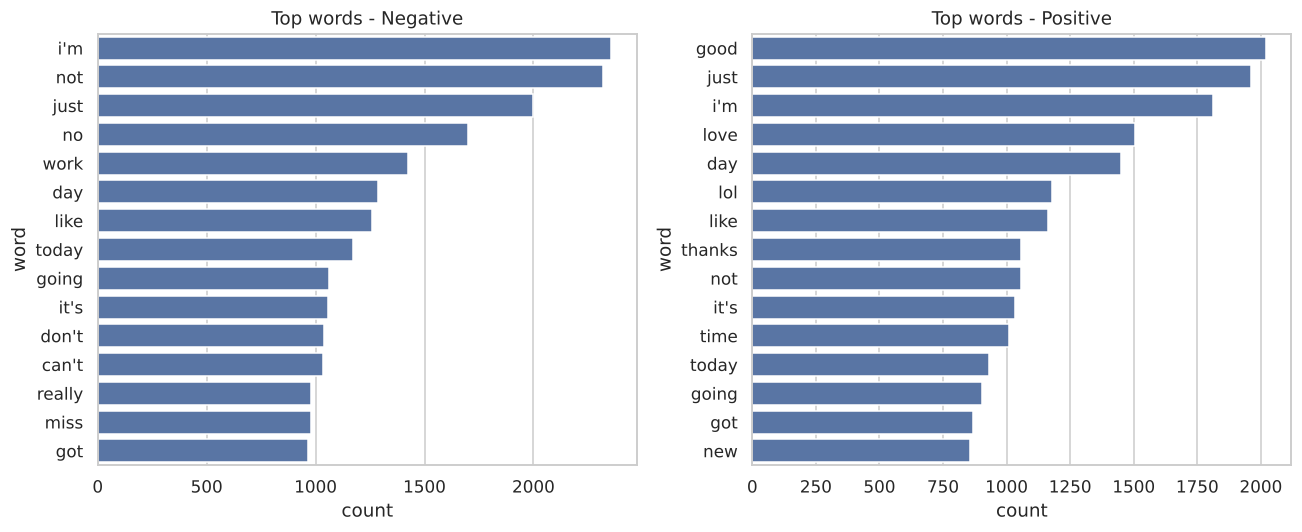

In [10]:
def top_words(texts, n=15):
    counter = Counter(word for text in texts for word in text.split())
    return pd.DataFrame(counter.most_common(n), columns=["word", "count"])


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (label, name) in zip(axes, LABELS.items()):
    words = top_words(sample.loc[sample["target"] == label, "clean_text"])
    sns.barplot(data=words, x="count", y="word", ax=ax)
    ax.set_title(f"Top words - {name}")

plt.tight_layout()
plt.show()

## 7. Questions to answer after running the notebook

- Are the classes balanced?
- Do positive and negative tweets have similar lengths?
- How many tweets become empty after preprocessing? Is that a problem?
- Which words appear in the top list of both sentiments? What does that say about how useful raw word counts are?

The next step is turning these cleaned texts into numbers (TF-IDF) and training the classifiers - see `src/train.py`.

## 8. What the data showed

- **Balanced classes:** exactly 800,000 negative and 800,000 positive tweets, so accuracy is a fair metric here.
- **Similar lengths:** positive and negative tweets have almost the same distribution (median of 69 characters and 12 words). Length alone does not separate the classes. A few tweets are longer than the old 140-character limit, probably because of HTML entities such as `&amp;`.
- **Data quality:** no missing values, but 18,534 tweets (about 1.2%) are duplicated. This is a small share, so they were kept.
- **Empty after preprocessing:** 301 of the 50,000 sampled tweets (0.60%) have nothing left after cleaning (only links or mentions). They carry no information and are removed before training, which is not a problem at this rate.
- **Frequent words overlap:** `just`, `i'm`, `day`, `like`, `not`, `it's`, `today`, `going` and `got` are in the top 15 of **both** sentiments. Raw word counts are therefore a weak signal. TF-IDF, which weighs a word by how rare it is across tweets, and bigrams, which keep pairs such as "not happy", help the model find the words that really change from one sentiment to the other.
